Weak ties
Part b

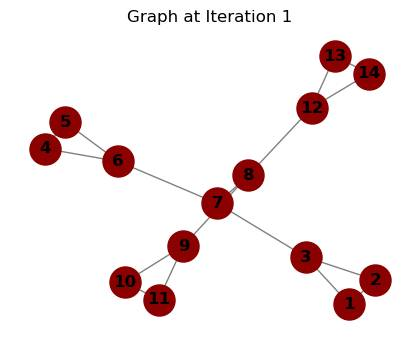

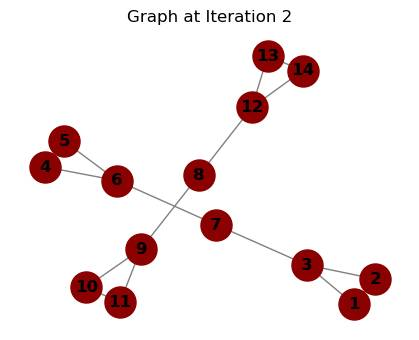

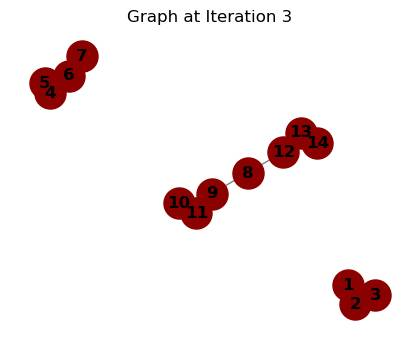

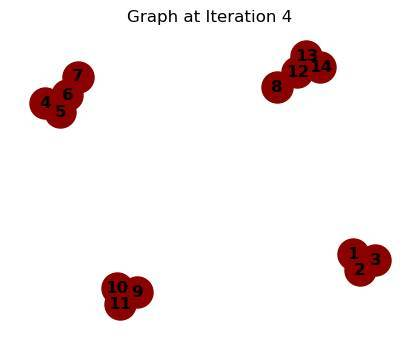

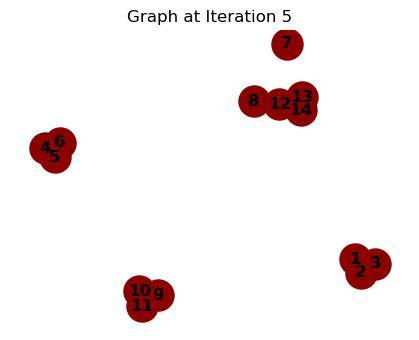

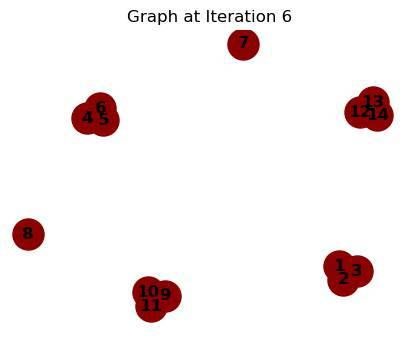

Maximum Modularity: 0.6913265306122449
Removed Edges: [(7, 8), (3, 7), (8, 9), (7, 6), (8, 12), (1, 2), (1, 3), (2, 3), (6, 4), (6, 5), (9, 10), (9, 11), (12, 13), (12, 14), (4, 5), (10, 11), (13, 14)]
Communities: ({1, 2, 3}, {7}, {8, 12, 13, 14}, {4, 5, 6}, {9, 10, 11})
Appropriate Threshold for Edge Betweenness Centrality: 0.13186813186813187


[Some figures were removed to keep the repository small; see report.pdf]


In [1]:
import networkx as nx
import matplotlib.pyplot as plt

def read_edges_from_file(file_path):
    edges = []
    with open(file_path, 'r') as file:
        for line in file:
            nodes = line.strip().split()
            if len(nodes) == 2:
                edges.append((int(nodes[0]), int(nodes[1])))
    return edges

def calculate_modularity(G, communities):
    return nx.algorithms.community.quality.modularity(G, communities)

def edge_betweenness_modularity_with_visualization(G):
    removed_edges = []
    max_modularity = 0
    best_communities = None
    best_threshold = 0
    iteration = 1
    while G.number_of_edges() > 0:
        plt.figure(figsize=(4,3))
        # To make sure the consistent random numbers (we set the seed)
        pos = nx.spring_layout(G, seed=79)  
        nx.draw(
            G,
            pos,
            with_labels=True,
            node_color='darkred',
            node_size=500,
            font_weight='bold',
            edge_color='gray'
        )
        plt.title(f"Graph at Iteration {iteration}")
        plt.show()

        edge_betweenness = nx.edge_betweenness_centrality(G)
        edge_to_remove = max(edge_betweenness, key=edge_betweenness.get)
        removed_edges.append(edge_to_remove)
        G.remove_edge(*edge_to_remove)
        # To make sure that the graph still has edges before calculating communities. Else we will break (This the break condition)
        if G.number_of_edges() == 0:
            break
        # Detecting communities
        communities = list(nx.algorithms.community.girvan_newman(G))
        best_partition = max(communities, key=lambda c: calculate_modularity(G, c))
        # Calculating modularity
        current_modularity = calculate_modularity(G, best_partition)
        if current_modularity > max_modularity:
            max_modularity = current_modularity
            best_communities = best_partition
            best_threshold = edge_betweenness[edge_to_remove]
        iteration += 1
    return max_modularity, removed_edges, best_communities, best_threshold

file_path = 'F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Analysis of Complex Networks/Assignments/HW2/Answer/Dataset/Weak-ties/second-graph.txt'
edges = read_edges_from_file(file_path)
G = nx.Graph()
G.add_edges_from(edges)

max_mod, removed_edges, communities, threshold = edge_betweenness_modularity_with_visualization(G)
print("Maximum Modularity:", max_mod)
print("Removed Edges:", removed_edges)
print("Communities:", communities)
print("Appropriate Threshold for Edge Betweenness Centrality:", threshold)